# [Lab Session 4](deconvolution.ipynb)

In [62]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

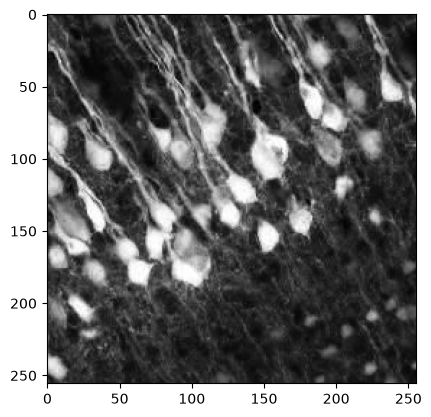

In [63]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [64]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

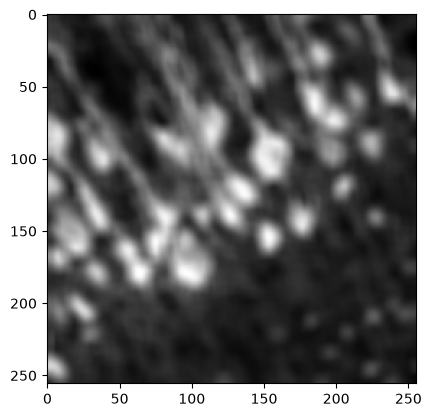

In [65]:
img_psf = conv(img, psf, mode="same", boundary="symm")
plt.figure()
plt.imshow(img_psf, "gray")

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

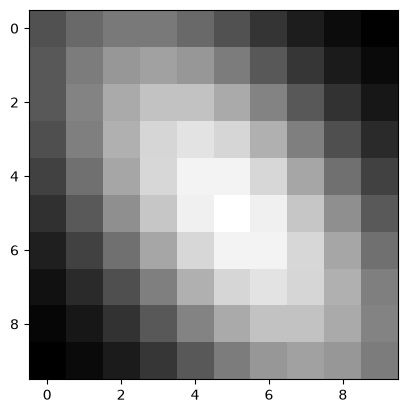

In [66]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

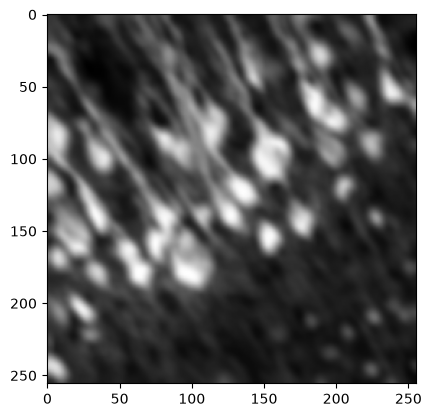

In [67]:
img_psf_gaus = conv(img, create_psf(psf_size), mode="same", boundary="symm")
plt.figure()
plt.imshow(img_psf_gaus, "gray")

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [68]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)

    while n_iterations > 0 :
        img_deconv = img_deconv * (conv(image / conv(img_deconv, psf, mode="same", boundary="symm"), np.flip(psf), mode="same", boundary="symm"))
        n_iterations = n_iterations -1
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [69]:
deconv_img = richardson_lucy_deconvolution(img_psf, psf, 20)

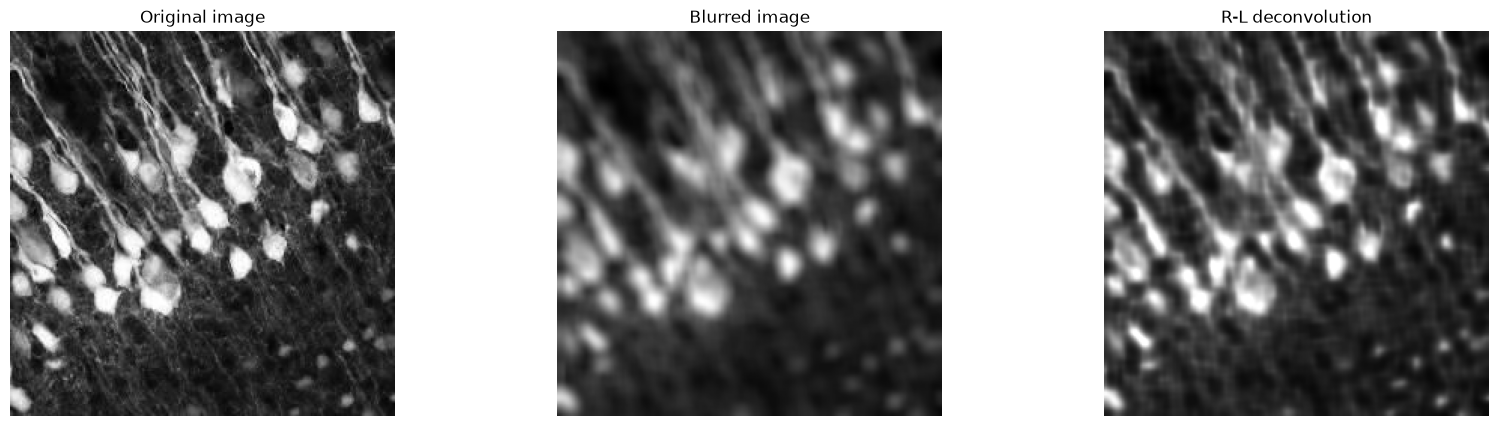

In [70]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(deconv_img, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [71]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 10
noise = noise / reduce_factor

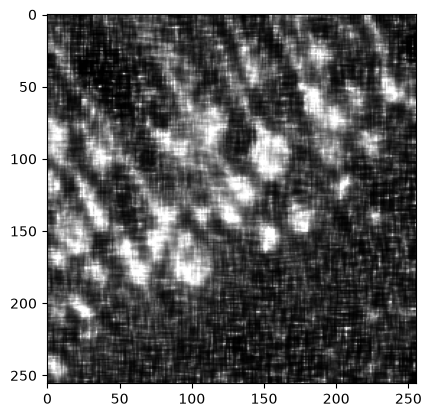

In [72]:
img_psf_noise = img_psf + noise
deconv_img_noise = richardson_lucy_deconvolution(img_psf_noise, psf, 20)
plt.figure()
plt.imshow(deconv_img_noise, "gray")

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

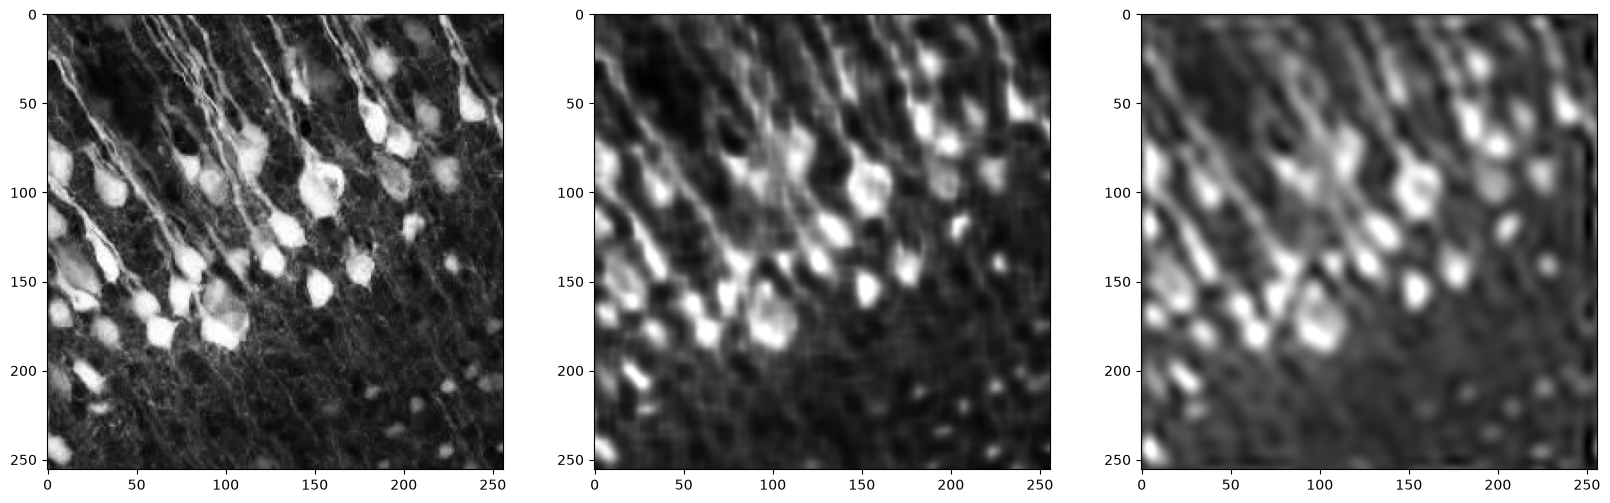

In [73]:
img_restore_wiener = wiener(img_psf, psf, balance=1.0, clip=True)

plt.figure(figsize=(20,7))
plt.subplot(1, 3, 1)
plt.imshow(img, "gray")
plt.subplot(1, 3, 2)
plt.imshow(deconv_img, "gray")
plt.subplot(1, 3, 3)
plt.imshow(img_restore_wiener, "gray")

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

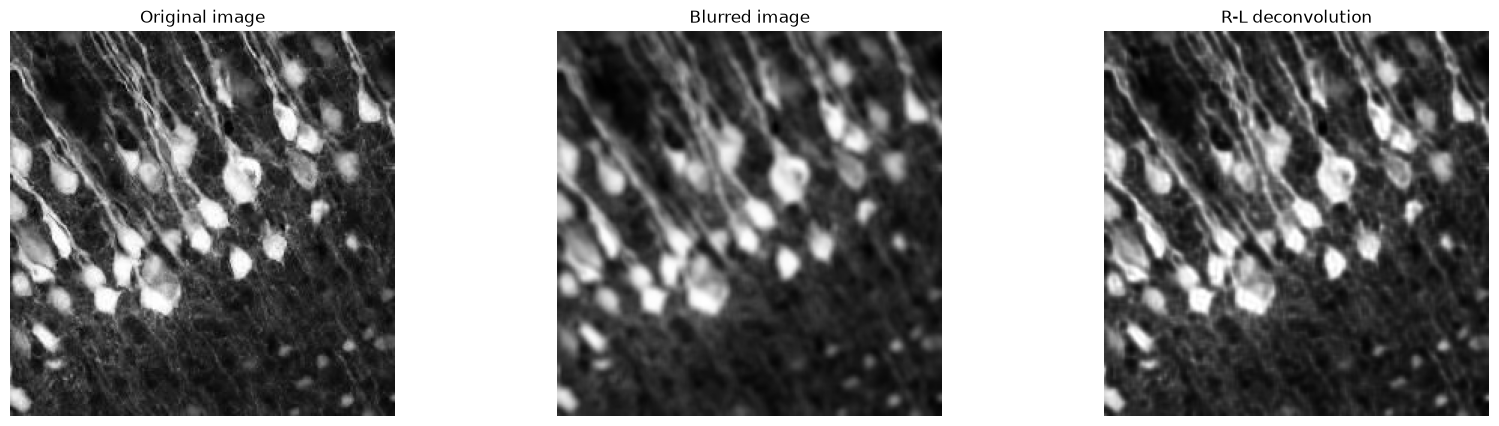

In [74]:
psf_size_5 = 5
psf_5 = np.ones((psf_size_5, psf_size_5)) / psf_size_5 ** 2
img_psf_5 = conv(img, psf_5, mode="same", boundary="symm")

img_rld_5 = richardson_lucy_deconvolution(img_psf_5, psf_5, 20)

plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf_5, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_rld_5, 'gray')
plt.title('R-L deconvolution')
plt.show()

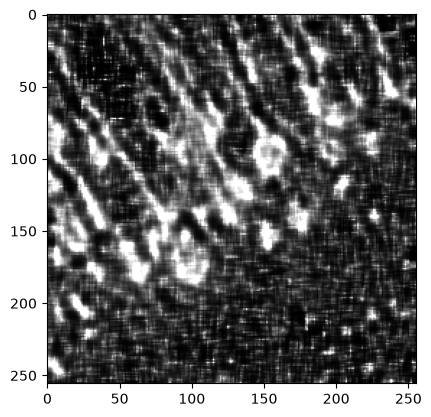

In [75]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 10
noise = noise / reduce_factor

img_psf_5_noise = img_psf_5 + noise
img_rld_5_noise = richardson_lucy_deconvolution(img_psf_5_noise, psf, 20)
plt.figure()
plt.imshow(img_rld_5_noise, "gray")

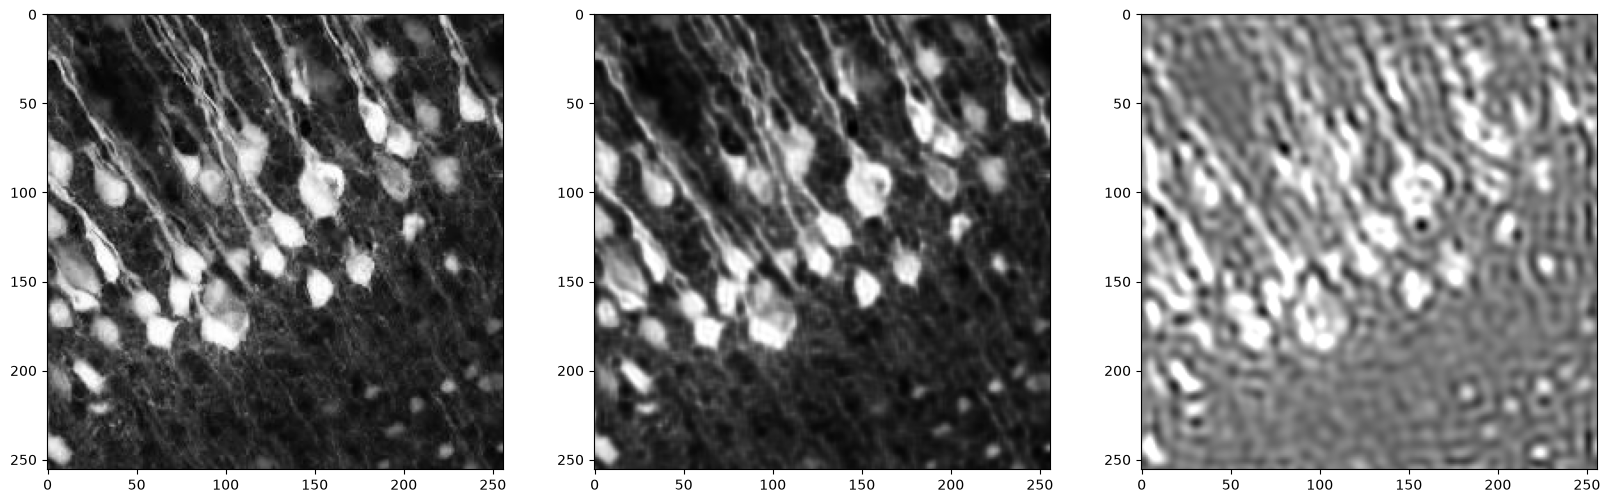

In [76]:
img_wd_5 = wiener(img_psf_5, psf, balance=0.1, clip=True)

plt.figure(figsize=(20,7))
plt.subplot(1, 3, 1)
plt.imshow(img, "gray")
plt.subplot(1, 3, 2)
plt.imshow(img_rld_5, "gray")
plt.subplot(1, 3, 3)
plt.imshow(img_wd_5, "gray")

**[Task 8.]()** Use a wrong PSF to restore the image

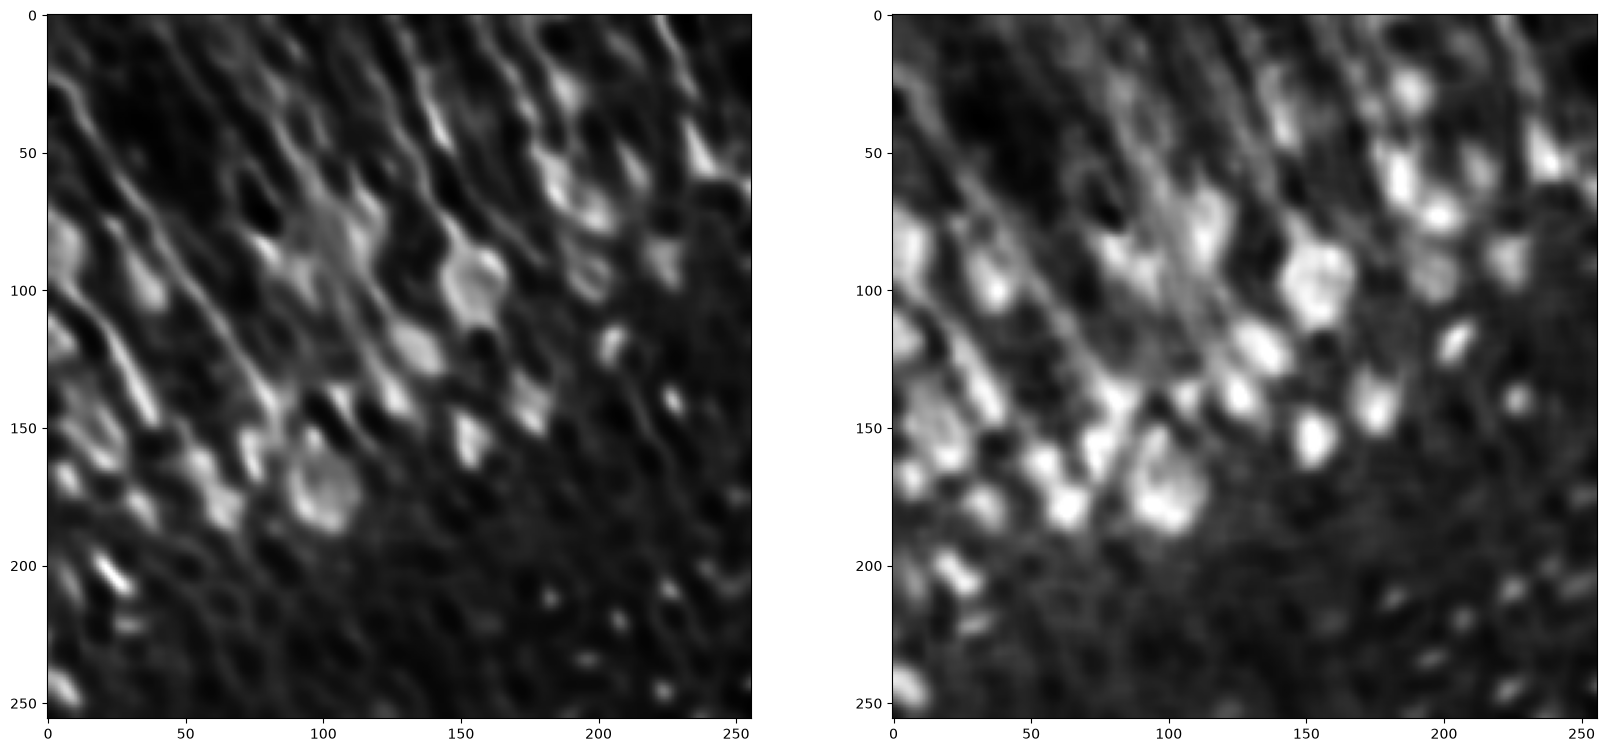

In [77]:
img_psf_gaus = conv(img, create_psf(psf_size), mode="same", boundary="symm")
img_rld_unifromforgaus = richardson_lucy_deconvolution(img_psf_gaus, psf, 20)

img_rld_gausforuniform = richardson_lucy_deconvolution(img_psf, create_psf(psf_size), 20)

plt.figure(figsize=(20,10))
plt.subplot(1, 2, 1)
plt.imshow(img_rld_unifromforgaus, "gray")
plt.subplot(1, 2, 2)
plt.imshow(img_rld_gausforuniform, "gray")